# NFL Game Simulator

Simulates an upcoming game snap by snap, 20,000 times, from real nflverse play-by-play, then replays the most typical game with a live scoreboard, win probability, field, score chart and box scores.

**How a snap is simulated**
- Each play is resampled from real 2025–26 nflverse plays: the offense's own plays, plays the defense has allowed, and league plays.
- **Defense and offense features drive the outcome.** Opponent-adjusted ridge ratings give every team a pass/run offense and pass/run defense rating (EPA per play, adjusted for schedule and shrunk toward average). Each matchup shifts the play distribution so its expected EPA = league + offense rating + defense rating. Against a weak run defense every carry is better, so the running back's line, drives and final score all move.
- **Game-level form.** Each simulated game draws, for each offense, a good-or-bad passing day and a run/pass lean (both average to zero). That gives real-looking bad days: QB passing yards are calibrated so about 12% of games land under 150, as in real 2025-26 games. Team pass rates come from normal situations only; hurry-up, late-lead and trailing-big pass rates are the league's measured rates.
- **Defensive looks on every snap.** The defense picks a look from its tendencies in that situation (early down, 3rd & short, 3rd & long), adjusted for what this offense usually faces: coverage shell (man, Cover 2, Cover 3, quarters — nflverse participation data, 2025 only until 2026 is published), blitz or not (FTN charting, 2025-26) and, on runs, box count (light, 7-man, stacked). Outcomes lean on real plays against that look, including the ball carrier's or target's own. Free data has no run-scheme labels, so box count stands in for run defense. Looks reshape outcomes without moving each team's overall strength.
- **Each player's own play-by-play matters.** The ball carrier or target is chosen first by recent usage, then the outcome is drawn largely from *his own* 2025–26 plays (shrunk toward the team the fewer plays he has), with the defense matchup applied on top. An efficient back gains more per carry than his backup in the same offense.
- **The XGBoost probability is a light nudge, not the answer.** `MODEL_WEIGHT` blends the matchup-only win probability with the model in logit space (default 25% model). A close model pick can flip when the matchups disagree.

Simulated games are plausible outcomes, not predictions of specific plays. Kick and punt return touchdowns and timeouts are not modeled.

## Settings

- `GAME`: a game id like `2026_09_JAX_BAL` or a team like `PHI`; `None` picks the closest game.
- `N_SIMS`: number of simulated games (20,000 takes about 1.5 minutes).
- `MODEL_WEIGHT`: 0 uses only the play-by-play matchups, 1 forces the model's win probability.
- `PROBABILITY_SOURCE`: `"xgb"` for the XGBoost model, `"ensemble"` for the blended model.
- `REFRESH_DATA`: `True` downloads the latest nflverse data.
- `RUN_SLATE`: `True` also simulates every game this week (slow).
- Injured players (`out_players`) and players returning from injury (`returning_players`) come from `nfl_weekly_config.json`.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import nfl_model_pipeline as nfl
import nfl_game_sim as sim

warnings.filterwarnings("ignore", category=pd.errors.DtypeWarning)

weekly_config = json.loads(Path("nfl_weekly_config.json").read_text())

SEASON, WEEK = weekly_config["season"], weekly_config["week"]
MODEL_PATH = Path(weekly_config["model_path"])
QB_OVERRIDES = weekly_config["qb_overrides"]
OUT_PLAYERS = weekly_config.get("out_players", {})
RETURNING_PLAYERS = weekly_config.get("returning_players", {})
GAME = "2026_09_JAX_BAL"
N_SIMS = 20_000
CALIBRATION_SIMS = 10_000
MODEL_WEIGHT = 0.25
PROBABILITY_SOURCE = "xgb"
REFRESH_DATA = False
SEED = 2026
RUN_SLATE = False

## Load play-by-play and fit the league context

In [2]:
league = sim.League.from_cache(SEASON, refresh=REFRESH_DATA)
print(f"Play pool: {len(league.pool['epa']):,} plays from {SEASON - 1}-{SEASON}; "
      f"{SEASON} play-by-play through week {int(league.current.week.max())}.")
print(f"Penalty rate {league.penalty_rate:.1%} · XP {league.xp_rate:.1%} · two-point {league.two_point_rate:.1%}")

Play pool: 46,080 plays from 2025-2026; 2026 play-by-play through week 8.
Penalty rate 7.9% · XP 95.1% · two-point 48.6%


## Team offense and defense ratings

Opponent-adjusted EPA per play. Offense: higher is better. Defense: EPA **allowed**, so higher is worse.

In [3]:
ratings = league.ratings.copy()
ratings_view = ratings.assign(
    pass_off_rank=ratings.pass_offense.rank(ascending=False).astype(int),
    run_off_rank=ratings.run_offense.rank(ascending=False).astype(int),
    pass_def_rank=ratings.pass_defense.rank().astype(int),
    run_def_rank=ratings.run_defense.rank().astype(int),
).sort_values("run_defense", ascending=False)
display(ratings_view.style.format({c: "{:+.3f}" for c in ["pass_offense", "run_offense", "pass_defense", "run_defense"]})
        .background_gradient(subset=["pass_offense", "run_offense"], cmap="RdYlGn")
        .background_gradient(subset=["pass_defense", "run_defense"], cmap="RdYlGn_r"))

,pass_offense,pass_defense,run_offense,run_defense,pass_off_rank,run_off_rank,pass_def_rank,run_def_rank
team,,,,,,,,
NYG,-0.025,+0.004,+0.002,+0.055,20,16,17,32
DAL,+0.072,+0.144,+0.043,+0.041,7,7,32,31
BUF,+0.130,+0.041,+0.077,+0.037,1,2,25,30
CAR,-0.002,+0.019,+0.011,+0.029,15,15,20,29
NO,-0.034,+0.020,-0.050,+0.028,21,29,22,28
PHI,-0.077,-0.010,-0.025,+0.026,28,22,15,27
WAS,-0.006,+0.075,-0.021,+0.023,16,21,29,26
TEN,-0.143,+0.089,-0.019,+0.022,32,20,30,25
CIN,+0.059,+0.020,+0.020,+0.017,9,12,21,24


## Model probabilities for the week

In [4]:
week_predictions = nfl.predict_upcoming_week(MODEL_PATH, SEASON, WEEK, refresh=REFRESH_DATA, log=False,
                                             qb_overrides=QB_OVERRIDES)
probability_column = ("xgb_home_probability" if PROBABILITY_SOURCE == "xgb" and "xgb_home_probability" in week_predictions
                      else "home_win_probability")
week_predictions["model_home_probability"] = week_predictions[probability_column]
print(f"Week {WEEK}: {len(week_predictions)} upcoming games · probability source: {probability_column}")
display(week_predictions[["game_id", "gameday", "away_team", "away_qb_name", "home_team", "home_qb_name",
                          "model_home_probability", "home_win_probability"]]
        .style.format({"model_home_probability": "{:.1%}", "home_win_probability": "{:.1%}"}))

Week 8: 13 upcoming games · probability source: xgb_home_probability


,game_id,gameday,away_team,away_qb_name,home_team,home_qb_name,model_home_probability,home_win_probability
0,2026_08_ARI_DAL,2026-11-01 00:00:00,ARI,Jacoby Brissett,DAL,Dak Prescott,69.5%,69.3%
1,2026_08_ATL_TB,2026-11-01 00:00:00,ATL,Michael Penix Jr.,TB,Baker Mayfield,46.1%,52.2%
2,2026_08_BAL_BUF,2026-11-01 00:00:00,BAL,Lamar Jackson,BUF,Josh Allen,65.7%,71.3%
3,2026_08_CLE_PIT,2026-11-01 00:00:00,CLE,Deshaun Watson,PIT,Aaron Rodgers,57.1%,64.0%
4,2026_08_IND_JAX,2026-11-01 00:00:00,IND,Daniel Jones,JAX,Trevor Lawrence,69.8%,77.8%
5,2026_08_KC_DEN,2026-11-01 00:00:00,KC,Patrick Mahomes,DEN,Bo Nix,54.1%,57.8%
6,2026_08_LAC_LA,2026-11-01 00:00:00,LAC,Justin Herbert,LAR,Matthew Stafford,69.5%,71.5%
7,2026_08_LV_NYJ,2026-11-01 00:00:00,LV,Kirk Cousins,NYJ,Geno Smith,42.3%,43.5%
8,2026_08_MIN_DET,2026-11-01 00:00:00,MIN,Kyler Murray,DET,Jared Goff,57.2%,56.0%
9,2026_08_NE_MIA,2026-11-01 00:00:00,NE,Drake Maye,MIA,Malik Willis,40.7%,33.4%


## Pick a game and compare the matchups

In [5]:
if GAME is None:
    game = week_predictions.loc[(week_predictions.model_home_probability - .5).abs().idxmin()]
else:
    hit = week_predictions.loc[week_predictions.game_id.eq(GAME) | week_predictions.home_team.eq(GAME)
                               | week_predictions.away_team.eq(GAME)]
    if hit.empty:
        raise ValueError(f"{GAME} is not an upcoming week {WEEK} game")
    game = hit.iloc[0]
HOME, AWAY = game.home_team, game.away_team
print(f"{game.game_id}: {AWAY} ({game.away_qb_name}) at {HOME} ({game.home_qb_name}) · "
      f"model {HOME} win {game.model_home_probability:.1%}")
display(sim.matchup_table(league, HOME, AWAY).style.format({
    "offense EPA/play (+ better)": "{:+.3f}", "defense EPA allowed (+ worse)": "{:+.3f}", "expected edge": "{:+.3f}"})
    .background_gradient(subset=["expected edge"], cmap="RdYlGn", vmin=-.12, vmax=.12))
print("Defensive looks each defense is expected to show this offense:")
display(sim.look_table(league, HOME, AWAY).set_index(["defense", "vs offense"]).style.format("{:.0%}"))

2026_08_LV_NYJ: LV (Kirk Cousins) at NYJ (Geno Smith) · model NYJ win 42.3%


,offense,play,offense EPA/play (+ better),offense rank,defense,defense EPA allowed (+ worse),defense rank (32 = worst),expected edge
0,LV,pass,-0.022,18,NYJ,+0.068,27,+0.046
1,LV,run,-0.111,32,NYJ,-0.013,10,-0.124
2,NYJ,pass,-0.063,24,LV,+0.039,24,-0.024
3,NYJ,run,-0.033,23,LV,+0.001,17,-0.032


Defensive looks each defense is expected to show this offense:


,,Man coverage,Cover 2,Cover 3,Quarters,Blitz (early downs),Blitz (3rd & long),Light box (early-down runs),7-man box (early-down runs),Stacked box (8+) (early-down runs)
defense,vs offense,,,,,,,,,
NYJ,LV,45%,21%,22%,12%,31%,37%,45%,43%,11%
LV,NYJ,30%,22%,34%,14%,24%,29%,44%,49%,7%


## Simulate

Simulated 100,000 separate games (100,000 distinct seeds) in 8 min 54 s.


,value
model home win %,42.3%
play-by-play only home win %,44.7%
simulated home win %,43.3%
ties %,0.9%
overtime %,5.7%
LV median points,21
NYJ median points,20
median total,40
median margin (NYJ),-3
EPA tilt,-0.004


Model pick: LV · simulation pick: LV


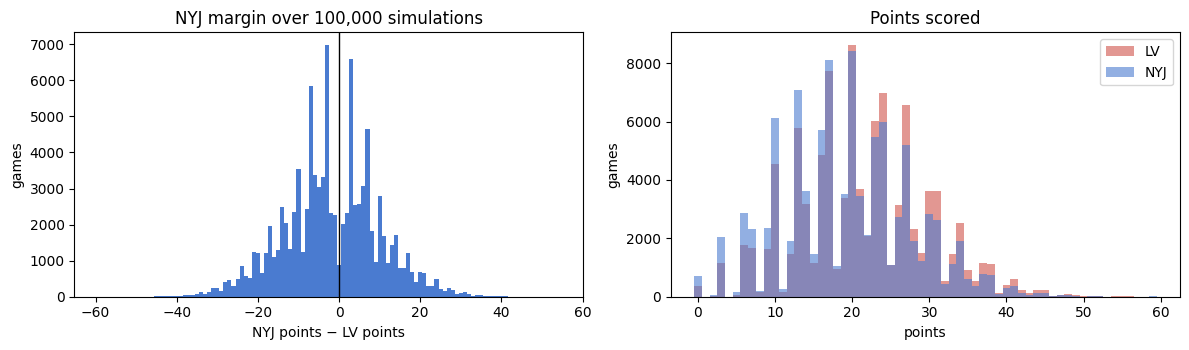

In [6]:
import time
started = time.perf_counter()
result = sim.simulate_game(league, HOME, AWAY, game.model_home_probability, n=N_SIMS, model_weight=MODEL_WEIGHT,
                           seed=SEED, home_qb=game.home_qb_name, away_qb=game.away_qb_name,
                           calibration_sims=CALIBRATION_SIMS, game_id=game.game_id,
                           out_players=OUT_PLAYERS, returning_players=RETURNING_PLAYERS)
minutes, seconds = divmod(round(time.perf_counter() - started), 60)
print(f"Simulated {result.games.sim.nunique():,} separate games ({result.games.seed.nunique():,} distinct seeds) "
      f"in {minutes} min {seconds} s.")
summary = result.summary()
display(pd.DataFrame({"value": [f"{v:.1%}" if k.endswith("%") else f"{v:+.3f}" if k == "EPA tilt" else f"{v:,.0f}"
                                 for k, v in summary.items()]}, index=summary.index))
model_pick = HOME if result.model_probability >= .5 else AWAY
sim_pick = HOME if result.home_win_rate >= .5 else AWAY
noise = 2 * np.sqrt(result.home_win_rate * (1 - result.home_win_rate) / len(result.games))
flip_note = "" if model_pick == sim_pick else (
    "  ← the matchups flip the pick" if abs(result.home_win_rate - .5) > noise else "  (within simulation noise: toss-up)")
print(f"Model pick: {model_pick} · simulation pick: {sim_pick}{flip_note}")

games = result.games
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
margin = games.home_score - games.away_score
axes[0].hist(margin, bins=np.arange(margin.min() - .5, margin.max() + 1.5), color="#4a7bd0")
axes[0].axvline(0, color="black", lw=1)
axes[0].set(title=f"{HOME} margin over {len(games):,} simulations", xlabel=f"{HOME} points − {AWAY} points", ylabel="games")
for team, column, color in [(AWAY, "away_score", "#d0524a"), (HOME, "home_score", "#4a7bd0")]:
    axes[1].hist(games[column], bins=np.arange(-.5, 60.5), alpha=.6, label=team, color=color)
axes[1].set(title="Points scored", xlabel="points", ylabel="games")
axes[1].legend()
plt.tight_layout()
plt.show()

## Watch the most typical game

The replay is a real simulated game, the one closest to the median on score, team yards, turnovers and each team's main passer, rusher and two receivers — like RotoBot's "most typical game". Press play. Use the speed buttons or the slider to scrub; **Final** jumps to the end. A standalone copy is saved under `output/simulations/` so you can open it in a browser. To watch a different simulation, pass `sim=` (0-based) to `show_replay`.

In [7]:
TYPICAL = result.typical_sim()
replay_frame, replay_path = sim.show_replay(result, TYPICAL)
print(f"Simulation {TYPICAL + 1} of {len(result.games):,} · saved to {replay_path}")
display(replay_frame)

Simulation 88408 of 100,000 · saved to output/simulations/2026_08_LV_NYJ_sim88408.html


## Box score of that game

In [8]:
typical_game = result.replay(TYPICAL)
print(f"Final: {AWAY} {typical_game.score[AWAY]} – {HOME} {typical_game.score[HOME]}")
for team, sections in sim.box_tables(typical_game, league).items():
    print(f"\n===== {team} =====")
    for title, table in sections.items():
        if len(table):
            print(title)
            display(table)

Final: LV 20 – NYJ 17

===== LV =====
Passing


,player,C/ATT,pass_yds,pass_td,pass_int,sacked
0,Kirk Cousins,23/30,284,1,0,4


Rushing


,player,rush_car,rush_yds,rush_td
0,Ashton Jeanty,15,35,1
1,Mike Washington Jr.,6,16,0
2,Kirk Cousins,3,9,0
3,Connor Heyward,1,3,0
4,Dylan Laube,1,-5,0


Receiving


,player,rec,tgt,rec_yds,rec_td
0,Ashton Jeanty,6,7,71,1
1,Tre Tucker,6,8,68,0
2,Brock Bowers,5,7,67,0
3,Cody White,2,2,39,0
4,Malik Benson,2,2,27,0
5,Michael Mayer,1,1,9,0
6,Jalen Nailor,1,3,3,0


... (10 outputs left out)

Kicking


,player,fgm,fga,xpm,xpa
0,Bradley Pinion,1,1,2,2


Defense


,player,def_sack,def_int
0,Kingsley Enagbare,1,0
1,Nate Lynn,1,0
2,Demario Davis,2,0


## Player projections across every simulation

Averages over all simulated games, plus the share of games with a rushing or receiving touchdown. These are where the defensive matchups show up: a weak run defense lifts the opposing backs' averages.

In [9]:
projections = result.projections()
for team in (AWAY, HOME):
    p = projections.loc[projections.team.eq(team)]
    print(f"\n===== {team} =====")
    display(p.loc[p.pass_att.ge(1), ["player", "pos", "pass_cmp", "pass_att", "pass_yds", "pass_td", "pass_int"]]
            .sort_values("pass_att", ascending=False).round(1))
    display(p.loc[p.rush_car.ge(.5), ["player", "pos", "rush_car", "rush_yds", "rush_td", "anytime_td"]]
            .sort_values("rush_yds", ascending=False).round(2).head(5))
    display(p.loc[p.tgt.ge(.5), ["player", "pos", "tgt", "rec", "rec_yds", "rec_td", "anytime_td"]]
            .sort_values("rec_yds", ascending=False).round(2).head(7))


===== LV =====


,player,pos,pass_cmp,pass_att,pass_yds,pass_td,pass_int
0,Kirk Cousins,QB,24.0,35.7,266.9,1.8,0.8


,player,pos,rush_car,rush_yds,rush_td,anytime_td
13,Ashton Jeanty,RB,13.01,42.79,0.19,0.47
17,Mike Washington Jr.,RB,6.00,23.58,0.11,0.14
0,Kirk Cousins,QB,2.40,16.36,0.07,0.07
12,Dylan Laube,RB,0.87,3.02,0.02,0.05


,player,pos,tgt,rec,rec_yds,rec_td,anytime_td
11,Brock Bowers,TE,7.97,5.55,64.31,0.43,0.36
9,Tre Tucker,WR,7.11,4.55,57.41,0.34,0.30
13,Ashton Jeanty,RB,6.20,4.42,41.12,0.41,0.47
10,Michael Mayer,TE,4.78,3.39,34.66,0.17,0.16
6,Jalen Nailor,WR,3.05,1.86,21.93,0.15,0.14
3,Cody White,WR,2.80,1.74,21.11,0.16,0.15
18,Malik Benson,WR,1.15,0.71,7.58,0.05,0.05



===== NYJ =====


,player,pos,pass_cmp,pass_att,pass_yds,pass_td,pass_int
20,Geno Smith,QB,22.4,34.1,235.0,1.3,0.7


,player,pos,rush_car,rush_yds,rush_td,anytime_td
32,Braelon Allen,RB,18.12,77.60,0.47,0.46
20,Geno Smith,QB,3.53,21.82,0.10,0.10
33,Isaiah Davis,RB,2.43,10.15,0.06,0.11
31,Isaiah Williams,WR,0.54,2.30,0.01,0.08


,player,pos,tgt,rec,rec_yds,rec_td,anytime_td
27,Garrett Wilson,WR,8.56,5.58,60.43,0.37,0.32
35,Mason Taylor,TE,4.81,3.23,30.92,0.18,0.17
38,Omar Cooper Jr.,WR,3.57,2.44,29.46,0.18,0.17
32,Braelon Allen,RB,4.55,3.06,28.78,0.13,0.46
37,Kenyon Sadiq,TE,3.97,2.60,26.59,0.14,0.13
34,Adonai Mitchell,WR,2.52,1.44,16.31,0.09,0.09
31,Isaiah Williams,WR,1.89,1.29,13.04,0.07,0.08


## Player props

Share of the simulated games where a player clears a line. `PROPS` checks specific lines (player name, prop, line); the board lists, for every player and prop, the most aggressive standard line that hits at least `PROP_THRESHOLD` of games.

Props: `pass_yds`, `pass_td`, `pass_cmp`, `pass_int`, `rush_yds`, `rush_car`, `rec`, `rec_yds`, `rush_rec_yds`, `anytime_td`. These come only from the simulation (no sportsbook data) and have not been checked against real results yet.

`PROPS` is a list of (player, prop, line). Add `"under"` to `PROP_SIDES` to list unders too.

In [ ]:
PROPS = [(game.home_qb_name, "pass_yds", 230), (game.away_qb_name, "pass_yds", 230)]
PROP_THRESHOLD = 0.55
PROP_SIDES = ("over",)

samples, prop_players = result.player_samples()
checked = pd.DataFrame([sim.prop_probability(samples, prop_players, *prop) for prop in PROPS])
display(checked.style.format({"over": "{:.1%}", "under": "{:.1%}", "push": "{:.1%}", "average": "{:.1f}"}))
board = sim.prop_board(samples, prop_players, PROP_THRESHOLD, PROP_SIDES)
print(f"{len(board)} props hit at least {PROP_THRESHOLD:.0%} of {len(samples):,} simulated games")
display(board.style.format({"probability": "{:.1%}", "sim median": "{:g}"}))

## Every game this week

`matchup only` is the play-by-play simulation with no model input; `simulated` blends in the model with `MODEL_WEIGHT`. A pick counts as **flipped** only when the simulated win rate is more than two standard errors from 50%; closer games are marked *toss-up*. Off by default: set `RUN_SLATE = True` in the settings cell to run it. 5,000 games per matchup takes about 6 minutes; setting `SLATE_SIMS = N_SIMS` (20,000) takes about 17.

In [10]:
if not RUN_SLATE:
    print("Skipped. Set RUN_SLATE = True in the settings cell to simulate every game this week.")
else:
    SLATE_SIMS = 5_000
    slate = []
    for row in week_predictions.itertuples():
        r = sim.simulate_game(league, row.home_team, row.away_team, row.model_home_probability, n=SLATE_SIMS,
                              model_weight=MODEL_WEIGHT, seed=SEED, home_qb=row.home_qb_name,
                              away_qb=row.away_qb_name, calibration_sims=1_000, game_id=row.game_id,
                              out_players=OUT_PLAYERS, returning_players=RETURNING_PLAYERS)
        proj = r.projections()
        top = lambda team, stat: proj.loc[proj.team.eq(team)].nlargest(1, stat)
        lead_rb = {team: top(team, "rush_yds") for team in (row.home_team, row.away_team)}
        slate.append({
            "game": f"{row.away_team} @ {row.home_team}",
            "model home %": r.model_probability, "matchup only home %": r.raw_probability, "simulated home %": r.home_win_rate,
            "projected score": f"{row.away_team} {r.games.away_score.median():.0f} – {r.games.home_score.median():.0f} {row.home_team}",
            "model pick": row.home_team if r.model_probability >= .5 else row.away_team,
            "sim pick": row.home_team if r.home_win_rate >= .5 else row.away_team,
            "top rusher (avg yds)": " · ".join(f"{t}: {p.player.iloc[0]} {p.rush_yds.iloc[0]:.0f}" for t, p in lead_rb.items()),
        })
    slate = pd.DataFrame(slate)
    noise = 2 * np.sqrt(slate["simulated home %"] * (1 - slate["simulated home %"]) / SLATE_SIMS)
    clear = (slate["simulated home %"] - .5).abs() > noise
    slate["flipped"] = np.where(slate["model pick"].eq(slate["sim pick"]), "", np.where(clear, "FLIPPED", "toss-up"))
    display(slate.style.format({c: "{:.1%}" for c in ["model home %", "matchup only home %", "simulated home %"]})
            .apply(lambda r: ["background-color: #fff3c4" if r.flipped == "FLIPPED" else "" for _ in r], axis=1))

Skipped. Set RUN_SLATE = True in the settings cell to simulate every game this week.
